# Gaia DR3 Variable Stars: Data Audit and Exploratory Analysis

## Imports and Configuration

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from astropy.timeseries import LombScargle
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from gaia_variable_stars.config import SOURCE_FILE, PHOTOMETRY_FILE, CLEAN_FILE, FEATURE_FILE, FIGURES_ROOT, CLASSES, MIN_POINTS, SEED
from gaia_variable_stars.dataset import clean, label

FIGURES_ROOT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

MIN_PERIOD = 0.1
MAX_PERIOD = 1000.0
TOLERANCE = 0.10
MAX_DRIFT = 0.25

Status messages could not be retrieved


In [2]:
sources = pd.read_csv(SOURCE_FILE)
photometry = pd.read_csv(PHOTOMETRY_FILE, dtype={"transit_id": "string"})

if "band" in photometry:
    photometry = photometry.loc[photometry["band"].astype("string").str.upper().eq("G")].copy()
    photometry = photometry.rename(columns={
        "time": "g_transit_time", "mag": "g_transit_mag", "flux": "g_transit_flux",
        "flux_error": "g_transit_flux_error", "n_obs": "g_transit_n_obs",
        "rejected_by_variability": "variability_flag_g_reject"
    })

## Data Overview

### Schema and Source Integrity

In [3]:
source_cols = [
    "source_id", "class_name", "gaia_period", "gaia_period_origin",
    "ecl_lon", "ecl_lat", "bp_rp_color", "g_mean_magnitude", "n_g_epochs"
]

photometry_cols = [
    "source_id", "transit_id", "g_transit_time", "g_transit_mag",
    "g_transit_flux", "g_transit_flux_error", "variability_flag_g_reject"
]

assert set(source_cols).issubset(sources.columns), f"Missing source fields: {set(source_cols) - set(sources)}"
assert set(photometry_cols).issubset(photometry.columns), f"Missing photometry fields: {set(photometry_cols) - set(photometry)}"
assert sources["source_id"].is_unique and sources["class_name"].isin(CLASSES).all()
assert photometry["source_id"].isin(sources["source_id"]).all()

labeled = label(sources, photometry)

print("Sources:", len(sources))
print("Photometry:", len(photometry))

Sources: 2000
Photometry: 90126


In [4]:
display(sources["class_name"].value_counts().reindex(CLASSES, fill_value=0).to_frame("stars"))
display(sources.head(3))

,stars
class_name,
RR Lyrae,500
Cepheid,500
Eclipsing Binary,500
Long-Period Variable,500


,source_id,random_index,ra,dec,ecl_lon,ecl_lat,g_mean_magnitude,bp_mean_magnitude,rp_mean_magnitude,bp_rp_color,gaia_pf,gaia_p1_o,class_name,gaia_p2_o,gaia_frequency,gaia_period,gaia_period_origin,n_g_epochs
0,245251978451433728,1520826064,56.420114,46.682834,65.001881,26.115460,18.876387,19.333345,18.299236,1.034109,NaN,0.337184,RR Lyrae,NaN,NaN,0.337184,p1_o,37
1,5712669411241837184,1286622709,117.543461,-20.286212,124.754685,-40.459960,17.915445,18.395552,17.215742,1.179810,0.626575,NaN,RR Lyrae,NaN,NaN,0.626575,pf,45
2,5862160287770085632,343164423,198.333702,-63.766373,229.098839,-50.145385,20.633400,22.233725,19.275316,2.958408,0.637236,NaN,RR Lyrae,NaN,NaN,0.637236,pf,24


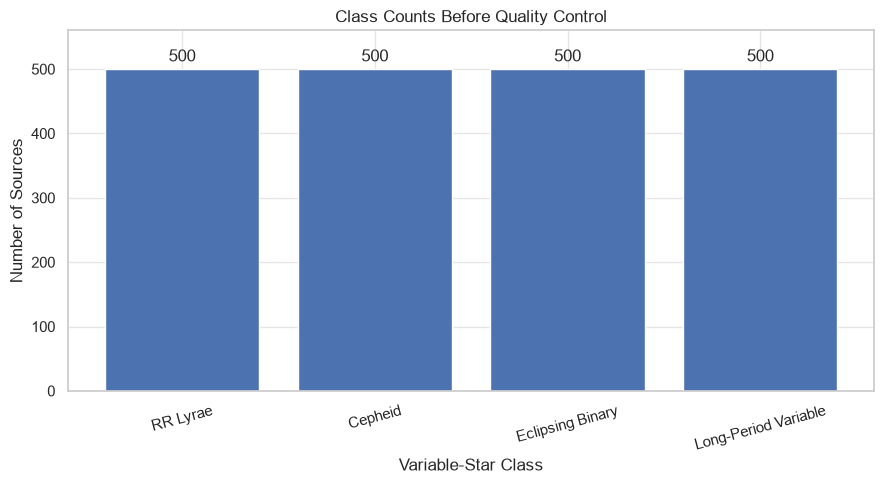

In [5]:
class_counts = sources["class_name"].value_counts().reindex(CLASSES, fill_value=0)

figure, axis = plt.subplots(figsize=(9, 5))

bars = axis.bar(CLASSES, class_counts)
axis.bar_label(bars, padding=3)

axis.set(
    ylim=(0, class_counts.max() * 1.12),
    xlabel="Variable-Star Class",
    ylabel="Number of Sources",
    title="Class Counts Before Quality Control"
)

axis.tick_params(axis="x", rotation=15)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "class_counts.png", dpi=160, bbox_inches="tight")
plt.show()

### Observation Quality Check

In [6]:
checks = labeled.copy()

for col in ["g_transit_time", "g_transit_mag", "g_transit_flux", "g_transit_flux_error"]:
    checks[col] = pd.to_numeric(checks[col], errors="coerce")

flag = checks["variability_flag_g_reject"].astype("string").str.strip().str.lower()

checks["missing_id"] = checks["transit_id"].isna()
checks["duplicate_id"] = checks["transit_id"].notna() & checks.duplicated(["source_id", "transit_id"], keep=False)
checks["duplicate_time"] = checks.duplicated(["source_id", "g_transit_time"], keep=False)
checks["invalid_time"] = ~np.isfinite(checks["g_transit_time"])
checks["invalid_magnitude"] = ~np.isfinite(checks["g_transit_mag"])
checks["invalid_flux"] = checks["g_transit_flux"].notna() & (~np.isfinite(checks["g_transit_flux"]) | checks["g_transit_flux"].le(0))
checks["missing_flux"] = checks["g_transit_flux"].isna()
checks["invalid_error"] = ~np.isfinite(checks["g_transit_flux_error"]) | checks["g_transit_flux_error"].le(0)
checks["unknown_flag"] = ~flag.isin(["true", "false", "1", "0", "1.0", "0.0", "t", "f"])
checks["rejected"] = flag.isin(["true", "1", "1.0", "t"])

issue_cols = [
    "missing_id", "duplicate_id", "duplicate_time", "invalid_time",
    "invalid_magnitude", "invalid_flux", "missing_flux", "invalid_error",
    "unknown_flag", "rejected"
]

issues = checks.groupby(["class_name", "source_id"])[issue_cols].any()
issues = issues.groupby("class_name").sum().reindex(CLASSES, fill_value=0)

display(issues.astype(int))

,missing_id,duplicate_id,duplicate_time,invalid_time,invalid_magnitude,invalid_flux,missing_flux,invalid_error,unknown_flag,rejected
class_name,,,,,,,,,,
RR Lyrae,0,0,56,175,175,0,175,175,0,333
Cepheid,0,0,175,350,350,0,350,350,0,444
Eclipsing Binary,0,0,105,257,257,0,257,257,0,399
Long-Period Variable,0,0,133,316,316,0,316,316,0,358


In [7]:
cleaned = clean(labeled)
retained = labeled.index.isin(cleaned.index)

print("Clean Observations:", len(cleaned))
print("Removed Observations:", len(labeled) - len(cleaned))

counts = pd.DataFrame({
    "raw": labeled.groupby("class_name").size(),
    "clean": cleaned.groupby("class_name").size()
})

display(counts.reindex(CLASSES).fillna(0).astype(int))

Clean Observations: 85243
Removed Observations: 4883


,raw,clean
class_name,,
RR Lyrae,20800,20010
Cepheid,23439,21672
Eclipsing Binary,22884,21685
Long-Period Variable,23003,21876


### Cleaning Consistency

In [8]:
saved = pd.read_csv(CLEAN_FILE, dtype={"transit_id": "string"})

cols = [
    col for col in [
        "source_id", "transit_id", "g_transit_time", "g_transit_mag",
        "g_transit_flux", "g_transit_flux_error"
    ] if col in saved and col in cleaned
]

sort_cols = [col for col in ["source_id", "g_transit_time", "transit_id"] if col in cols]

left = saved[cols].sort_values(sort_cols, na_position="last").reset_index(drop=True)
right = cleaned[cols].sort_values(sort_cols, na_position="last").reset_index(drop=True)

pd.testing.assert_frame_equal(left, right, check_dtype=False, rtol=1e-8, atol=1e-8)

print("Saved Cleaning Matches:", True)
print("Saved Observations:", len(saved))

Saved Cleaning Matches: True
Saved Observations: 85243


In [9]:
counts = cleaned.groupby("source_id").size().reindex(sources["source_id"], fill_value=0)
changed = sources["n_g_epochs"].ne(counts.to_numpy()).sum()

print("Changed Epoch Counts:", int(changed))

Changed Epoch Counts: 0


### Missingness and Period Origins

In [10]:
observed_cols = ["gaia_period", "ecl_lat", "g_mean_magnitude", "bp_rp_color"]
obs_cols = ["g_transit_time", "g_transit_mag", "g_transit_flux", "g_transit_flux_error"]

source_missing = sources.groupby("class_name")[observed_cols].agg(lambda x: x.isna().mean() * 100)
obs_missing = labeled.groupby("class_name")[obs_cols].agg(lambda x: x.isna().mean() * 100)

display(source_missing.reindex(CLASSES).round(2))
display(obs_missing.reindex(CLASSES).round(2))
display(pd.crosstab(sources["class_name"], sources["gaia_period_origin"]).reindex(CLASSES, fill_value=0))

,gaia_period,ecl_lat,g_mean_magnitude,bp_rp_color
class_name,,,,
RR Lyrae,0.0,0.0,0.0,7.4
Cepheid,0.0,0.0,0.0,0.0
Eclipsing Binary,0.0,0.0,0.0,0.8
Long-Period Variable,0.0,0.0,0.0,0.0


,g_transit_time,g_transit_mag,g_transit_flux,g_transit_flux_error
class_name,,,,
RR Lyrae,1.31,1.31,1.31,1.31
Cepheid,2.52,2.52,2.52,2.52
Eclipsing Binary,1.78,1.78,1.78,1.78
Long-Period Variable,2.14,2.14,2.14,2.14


gaia_period_origin,frequency,p1_o,pf
class_name,,,
RR Lyrae,0,188,312
Cepheid,0,193,307
Eclipsing Binary,500,0,0
Long-Period Variable,500,0,0


In [11]:
period_coverage = (sources.groupby("class_name")
                   .agg(stars=("source_id", "size"),
                        published_periods=("gaia_period", lambda value: value.gt(0).sum()),
                        median_period=("gaia_period", "median")).reindex(CLASSES)
                   )

period_coverage["selected_coverage_pct"] = 100 * period_coverage["published_periods"] / period_coverage["stars"]

display(period_coverage.round(2))

,stars,published_periods,median_period,selected_coverage_pct
class_name,,,,
RR Lyrae,500,500,0.48,100.0
Cepheid,500,500,3.15,100.0
Eclipsing Binary,500,500,0.42,100.0
Long-Period Variable,500,500,249.13,100.0


## Photometric Precision

In [12]:
quality = checks
quality["retained"] = retained

valid_error = (
    np.isfinite(quality["g_transit_flux"]) & quality["g_transit_flux"].gt(0)
    & np.isfinite(quality["g_transit_flux_error"]) & quality["g_transit_flux_error"].gt(0)
)

quality["relative_error"] = (quality["g_transit_flux_error"] / quality["g_transit_flux"]).where(valid_error)
quality["magnitude_error"] = 1.0857 * quality["relative_error"]

if "g_transit_n_obs" in labeled:
    quality["g_transit_n_obs"] = pd.to_numeric(labeled["g_transit_n_obs"], errors="coerce")

for col in ["variability_flag_g_reject", "photometry_flag_noisy_data"]:
    if col in labeled:
        states = labeled[col].astype("string").str.lower().fillna("missing")
        display(pd.crosstab(
            [labeled["class_name"], states], retained,
            rownames=["class", col], colnames=["retained"]
        ))
    elif col == "photometry_flag_noisy_data" and "other_flags" in labeled:
        print("Noisy Flag: Encoded in other_flags; not decoded.")

retained                                        False  True 
class                variability_flag_g_reject              
Cepheid              false                          0  21672
                     true                        1767      0
Eclipsing Binary     false                          0  21685
                     true                        1199      0
Long-Period Variable false                          0  21876
                     true                        1127      0
RR Lyrae             false                          0  20010
                     true                         790      0

In [13]:
summary_cols = ["g_transit_flux_error", "relative_error", "magnitude_error"]
if "g_transit_n_obs" in quality:
    summary_cols.append("g_transit_n_obs")

display(quality.groupby(["class_name", "retained"])[summary_cols].agg(["count", "median"]).round(4))

g_transit_flux_error          relative_error  \
                                             count   median          count   
class_name           retained                                                
Cepheid              False                    1176  28.7663           1176   
                     True                    21672  23.1242          21672   
Eclipsing Binary     False                     792  41.9841            792   
                     True                    21685   9.3836          21685   
Long-Period Variable False                     634  59.3107            634   
                     True                    21876  67.6062          21876   
RR Lyrae             False                     518  25.2688            518   
                     True                    20010  10.8334          20010   

                                      magnitude_error          
                               median           count  median  
class_name           retained                                  
Cepheid              False     0.0036            1176  0.0039  
                     True      0.0022           21672  0.0024  
Eclipsing Binary     False     0.0234             792  0.0254  
                     True      0.0073           21685  0.0079  
Long-Period Variable False     0.0036             634  0.0039  
                     True      0.0023           21876  0.0025  
RR Lyrae             False     0.0379             518  0.0411  
                     True      0.0064           20010  0.0069

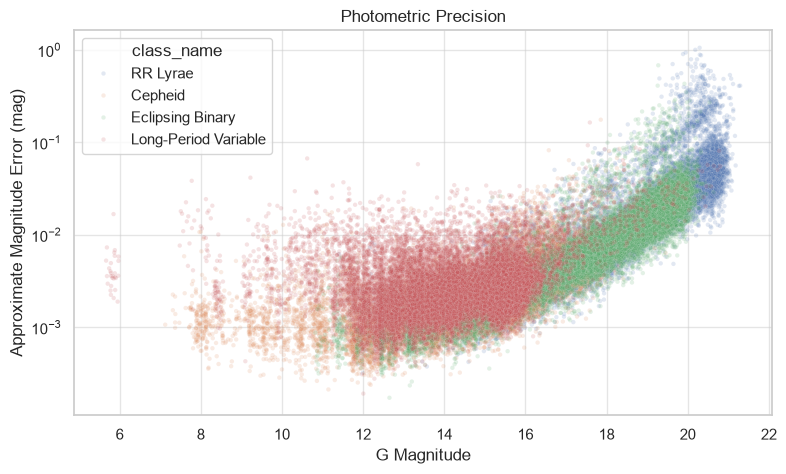

In [14]:
figure, axis = plt.subplots(figsize=(9, 5))

precision = quality.loc[quality["retained"] & quality["magnitude_error"].gt(0)]

sns.scatterplot(data=precision, x="g_transit_mag", y="magnitude_error", hue="class_name", hue_order=CLASSES, alpha=0.16, s=10, ax=axis)
axis.set(yscale="log", xlabel="G Magnitude", ylabel="Approximate Magnitude Error (mag)", title="Photometric Precision")

figure.savefig(FIGURES_ROOT / "01_photometric_precision.png", dpi=160, bbox_inches="tight")
plt.show()

## Star-Level Measurements

In [15]:
obs_cols = [
    "source_id", "g_transit_time", "g_transit_mag",
    "g_transit_flux", "g_transit_flux_error"
]

observations = cleaned[obs_cols].sort_values(["source_id", "g_transit_time"]).copy()

flux = pd.to_numeric(observations["g_transit_flux"], errors="coerce")
error = pd.to_numeric(observations["g_transit_flux_error"], errors="coerce")
valid_error = np.isfinite(flux) & flux.gt(0) & np.isfinite(error) & error.gt(0)

observations["magnitude_error"] = (1.0857 * error / flux).where(valid_error)
observations["time_gap"] = observations.groupby("source_id")["g_transit_time"].diff()
observations["short_gap"] = observations["time_gap"].between(0, 1, inclusive="neither")
observations["long_gap"] = observations["time_gap"].gt(30)
observations["new_group"] = observations["time_gap"].gt(1)

In [16]:
star_stats = observations.groupby("source_id").agg(
    n_epochs=("g_transit_time", "size"),
    time_span=("g_transit_time", lambda x: x.max() - x.min()),
    median_gap=("time_gap", "median"),
    positive_gaps=("time_gap", lambda x: x.gt(0).sum()),
    short_gaps=("short_gap", "sum"),
    long_gaps=("long_gap", "sum"),
    observing_groups=("new_group", lambda x: int(x.sum()) + 1),
    magnitude_mean=("g_transit_mag", "mean"),
    magnitude_std=("g_transit_mag", "std"),
    magnitude_skew=("g_transit_mag", "skew"),
    magnitude_kurt=("g_transit_mag", pd.Series.kurt),
    magnitude_mad=("g_transit_mag", lambda x: (x - x.median()).abs().median()),
    amplitude=("g_transit_mag", lambda x: x.quantile(0.95) - x.quantile(0.05)),
    median_error=("magnitude_error", "median"),
    valid_errors=("magnitude_error", "count")
).reset_index()

In [17]:
stars = sources.merge(star_stats, on="source_id", how="left", validate="one_to_one")

stars["n_epochs"] = stars["n_epochs"].fillna(0).astype(int)
stars["valid_errors"] = stars["valid_errors"].fillna(0).astype(int)
stars["abs_latitude"] = stars["ecl_lat"].abs()
stars["usable"] = stars["n_epochs"].ge(MIN_POINTS)
stars["short_gap_fraction"] = stars["short_gaps"] / stars["positive_gaps"].replace(0, np.nan)
stars["long_gap_fraction"] = stars["long_gaps"] / stars["positive_gaps"].replace(0, np.nan)
stars["amplitude_ratio"] = stars["amplitude"] / stars["median_error"].replace(0, np.nan)
stars["scatter_ratio"] = stars["magnitude_std"] / stars["median_error"].replace(0, np.nan)

print("Star Dataset:", len(stars))

display(
    stars.groupby("class_name")[
        ["n_epochs", "time_span", "median_gap", "amplitude", "median_error", "amplitude_ratio"]
    ].median().reindex(CLASSES).round(3)
)

Star Dataset: 2000


,n_epochs,time_span,median_gap,amplitude,median_error,amplitude_ratio
class_name,,,,,,
RR Lyrae,37.0,933.938,0.375,0.465,0.008,61.988
Cepheid,39.0,979.944,26.996,0.403,0.002,162.329
Eclipsing Binary,40.0,959.394,7.842,0.278,0.009,28.977
Long-Period Variable,42.0,959.343,17.467,0.318,0.002,134.554


,n,median,q1,q3
class_name,,,,
RR Lyrae,500,37.0,30.0,44.25
Cepheid,500,39.0,35.0,47.00
Eclipsing Binary,500,40.0,33.0,54.00
Long-Period Variable,500,42.0,36.0,50.00


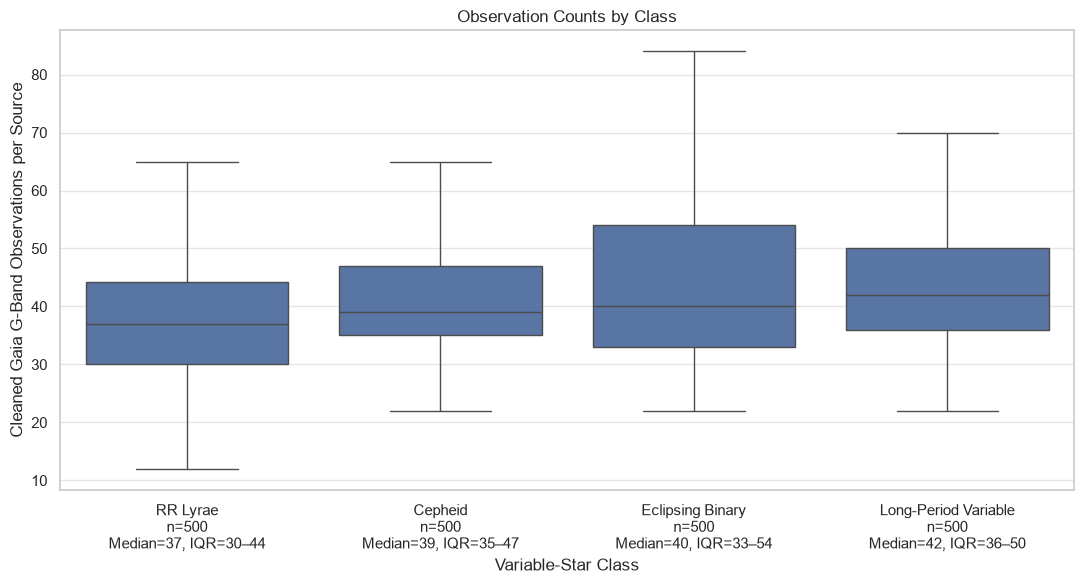

In [18]:
observation_summary = (
    stars.groupby("class_name")["n_epochs"]
    .agg(
        n="size",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reindex(CLASSES)
)

display(observation_summary.round(2))

figure, axis = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=stars,
    x="class_name",
    y="n_epochs",
    order=CLASSES,
    showfliers=False,
    ax=axis
)

axis.set_xticks(
    range(len(CLASSES)),
    [
        f"{name}\nn={observation_summary.loc[name, 'n']:.0f}\n"
        f"Median={observation_summary.loc[name, 'median']:.0f}, "
        f"IQR={observation_summary.loc[name, 'q1']:.0f}–"
        f"{observation_summary.loc[name, 'q3']:.0f}"
        for name in CLASSES
    ]
)

axis.set(
    xlabel="Variable-Star Class",
    ylabel="Cleaned Gaia G-Band Observations per Source",
    title="Observation Counts by Class"
)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "observation_counts.png", dpi=160, bbox_inches="tight")
plt.show()

### Measurement Bias and Cadence

In [19]:
rr_lyrae = stars.loc[stars["class_name"].eq("RR Lyrae")].copy()
rr_lyrae["missing_color"] = rr_lyrae["bp_rp_color"].isna()

display(
    rr_lyrae.groupby("missing_color")[
        ["g_mean_magnitude", "n_epochs", "median_error", "amplitude"]
    ].agg(["count", "median"]).round(3)
)

display(
    stars.groupby("class_name")[
        ["short_gap_fraction", "long_gap_fraction", "observing_groups", "scatter_ratio"]
    ].median().reindex(CLASSES).round(3)
)

print("Low Signal Stars:", int(stars["amplitude_ratio"].le(3).sum()))
print("High Scatter Stars:", int(stars["scatter_ratio"].gt(10).sum()))

g_mean_magnitude         n_epochs        median_error         \
                         count  median    count median        count median   
missing_color                                                                
False                      463  17.985      463   37.0          463  0.008   
True                        37  20.083       37   32.0           37  0.046   

              amplitude         
                  count median  
missing_color                   
False               463  0.476  
True                 37  0.407

,short_gap_fraction,long_gap_fraction,observing_groups,scatter_ratio
class_name,,,,
RR Lyrae,0.513,0.303,18.0,20.889
Cepheid,0.361,0.402,26.0,57.447
Eclipsing Binary,0.483,0.344,20.0,10.841
Long-Period Variable,0.435,0.333,24.0,44.772


Low Signal Stars: 0
High Scatter Stars: 1569


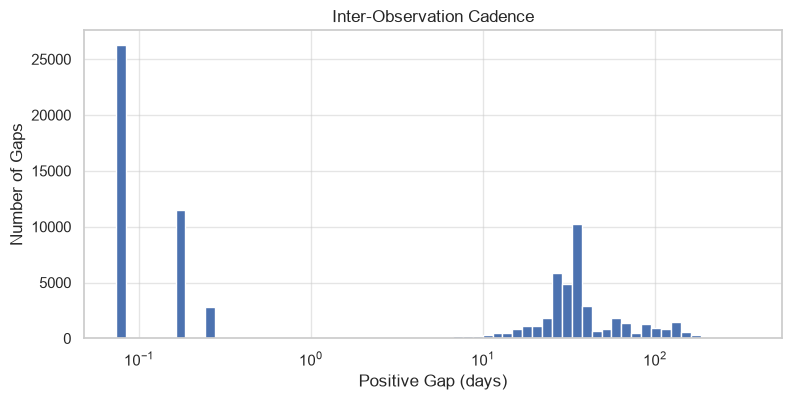

In [20]:
gaps = observations.loc[observations["time_gap"].gt(0), "time_gap"]

figure, axis = plt.subplots(figsize=(9, 4))
if len(gaps):
    axis.hist(gaps, bins=np.geomspace(gaps.min(), gaps.max() * 1.00001, 65))
    axis.set_xscale("log")
axis.set(xlabel="Positive Gap (days)", ylabel="Number of Gaps", title="Inter-Observation Cadence")

figure.savefig(FIGURES_ROOT / "02_observation_gaps.png", dpi=160, bbox_inches="tight")
plt.show()

## Sky Coverage and Sample Selection

In [21]:
stars["latitude_bin"] = pd.cut(stars["abs_latitude"], [0, 15, 30, 45, 60, 75, 90], include_lowest=True)

display(pd.crosstab(stars["class_name"], stars["latitude_bin"]).reindex(CLASSES, fill_value=0))
display(stars.groupby(["class_name", "latitude_bin"], observed=True)[["n_epochs", "median_gap", "short_gap_fraction"]].median().round(2))

latitude_bin,"(-0.001, 15.0]","(15.0, 30.0]","(30.0, 45.0]","(45.0, 60.0]","(60.0, 75.0]","(75.0, 90.0]"
class_name,,,,,,
RR Lyrae,152,106,140,64,22,16
Cepheid,46,19,39,66,25,305
Eclipsing Binary,129,127,0,0,52,192
Long-Period Variable,99,96,53,24,21,207


n_epochs  median_gap  short_gap_fraction
class_name           latitude_bin                                            
Cepheid              (-0.001, 15.0]      30.0       11.46                0.48
                     (15.0, 30.0]        42.0        0.21                0.54
                     (30.0, 45.0]        52.0        0.18                0.59
                     (45.0, 60.0]        53.5       13.82                0.46
                     (60.0, 75.0]        45.0       24.99                0.37
                     (75.0, 90.0]        37.0       28.17                0.32
Eclipsing Binary     (-0.001, 15.0]      44.0        0.18                0.61
                     (15.0, 30.0]        30.0       17.59                0.43
                     (60.0, 75.0]        58.0        0.25                0.54
                     (75.0, 90.0]        41.0       28.49                0.34
Long-Period Variable (-0.001, 15.0]      33.0        0.18                0.56
                     (15.0, 30.0]        47.0        0.18                0.57
                     (30.0, 45.0]        52.0        0.18                0.57
                     (45.0, 60.0]        59.0        0.18                0.52
                     (60.0, 75.0]        47.0       25.75                0.40
                     (75.0, 90.0]        39.0       27.67                0.33
RR Lyrae             (-0.001, 15.0]      35.0        0.21                0.54
                     (15.0, 30.0]        32.0        3.50                0.50
                     (30.0, 45.0]        40.0        0.25                0.52
                     (45.0, 60.0]        49.5       15.86                0.45
                     (60.0, 75.0]        40.5       27.67                0.36
                     (75.0, 90.0]        35.0       28.93                0.32

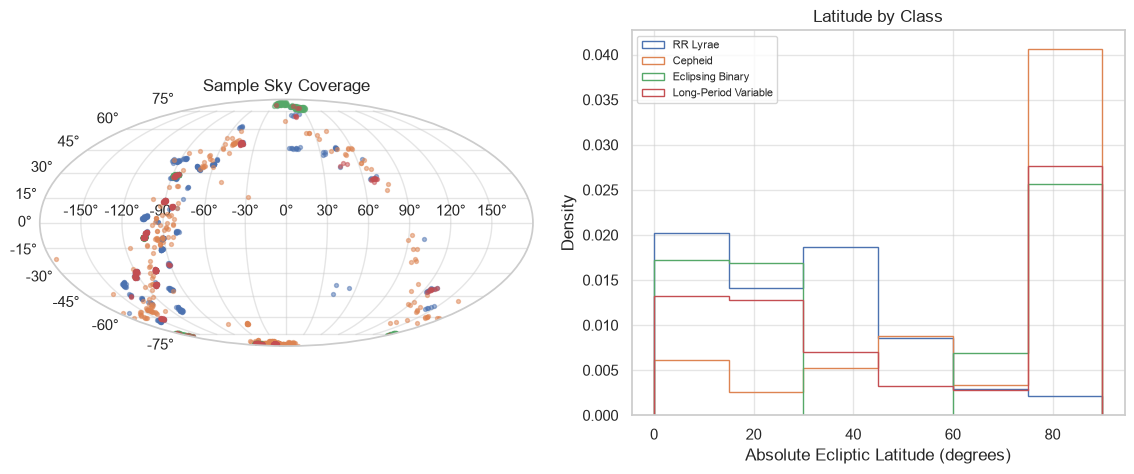

In [22]:
figure = plt.figure(figsize=(14, 5))

sky_axis = figure.add_subplot(121, projection="mollweide")
latitude_axis = figure.add_subplot(122)

for name in CLASSES:
    group = stars.loc[stars["class_name"].eq(name)].dropna(subset=["ecl_lon", "ecl_lat"])
    longitude = (group["ecl_lon"] + 180) % 360 - 180
    sky_axis.scatter(np.radians(longitude), np.radians(group["ecl_lat"]), s=8, alpha=0.5, label=name)
    latitude_axis.hist(group["abs_latitude"].dropna(), bins=[0, 15, 30, 45, 60, 75, 90], density=True, histtype="step", label=name)

sky_axis.set_title("Sample Sky Coverage")
sky_axis.grid(True)

latitude_axis.set(xlabel="Absolute Ecliptic Latitude (degrees)", ylabel="Density", title="Latitude by Class")
latitude_axis.legend(fontsize=8)

figure.savefig(FIGURES_ROOT / "03_sky_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

## Light Curves and Photometric Structure

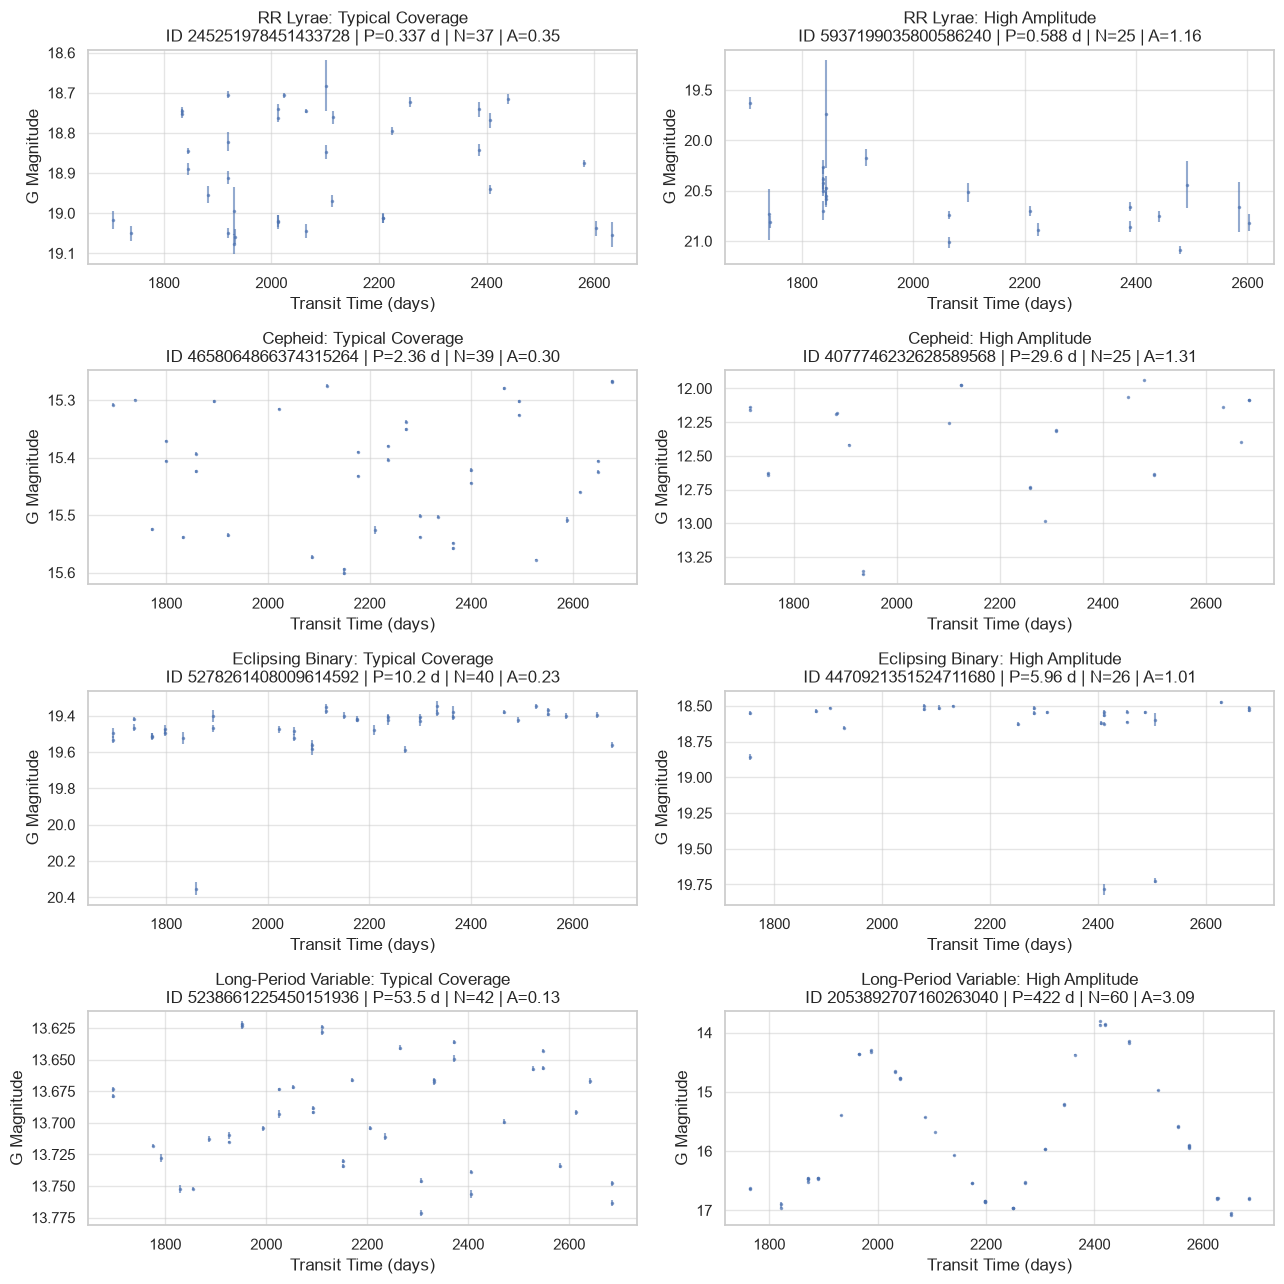

In [23]:
figure, axes = plt.subplots(4, 2, figsize=(13, 13))

for row, name in enumerate(CLASSES):
    group = stars.loc[stars["class_name"].eq(name) & stars["usable"]]

    if group.empty:
        for axis in axes[row]:
            axis.set_visible(False)
        continue

    typical = group.iloc[(group["n_epochs"] - group["n_epochs"].median()).abs().argmin()]
    high = group.loc[group["amplitude"].idxmax()]

    for axis, (label_name, star) in zip(axes[row], [("Typical Coverage", typical), ("High Amplitude", high)]):
        group_obs = observations.loc[observations["source_id"].eq(star["source_id"])]
        valid = group_obs["magnitude_error"].gt(0) & np.isfinite(group_obs["magnitude_error"])

        axis.errorbar(
            group_obs.loc[valid, "g_transit_time"], group_obs.loc[valid, "g_transit_mag"],
            yerr=group_obs.loc[valid, "magnitude_error"], fmt=".", ms=3, alpha=0.6
        )
        axis.scatter(
            group_obs.loc[~valid, "g_transit_time"],
            group_obs.loc[~valid, "g_transit_mag"], s=10
        )
        axis.invert_yaxis()
        axis.set(
            title=f"{name}: {label_name}\nID {int(star['source_id'])} | P={star['gaia_period']:.3g} d | N={star['n_epochs']} | A={star['amplitude']:.2f}",
            xlabel="Transit Time (days)", ylabel="G Magnitude"
        )

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "04_light_curves.png", dpi=160, bbox_inches="tight")
plt.show()

### Period–Amplitude and Color Relationships

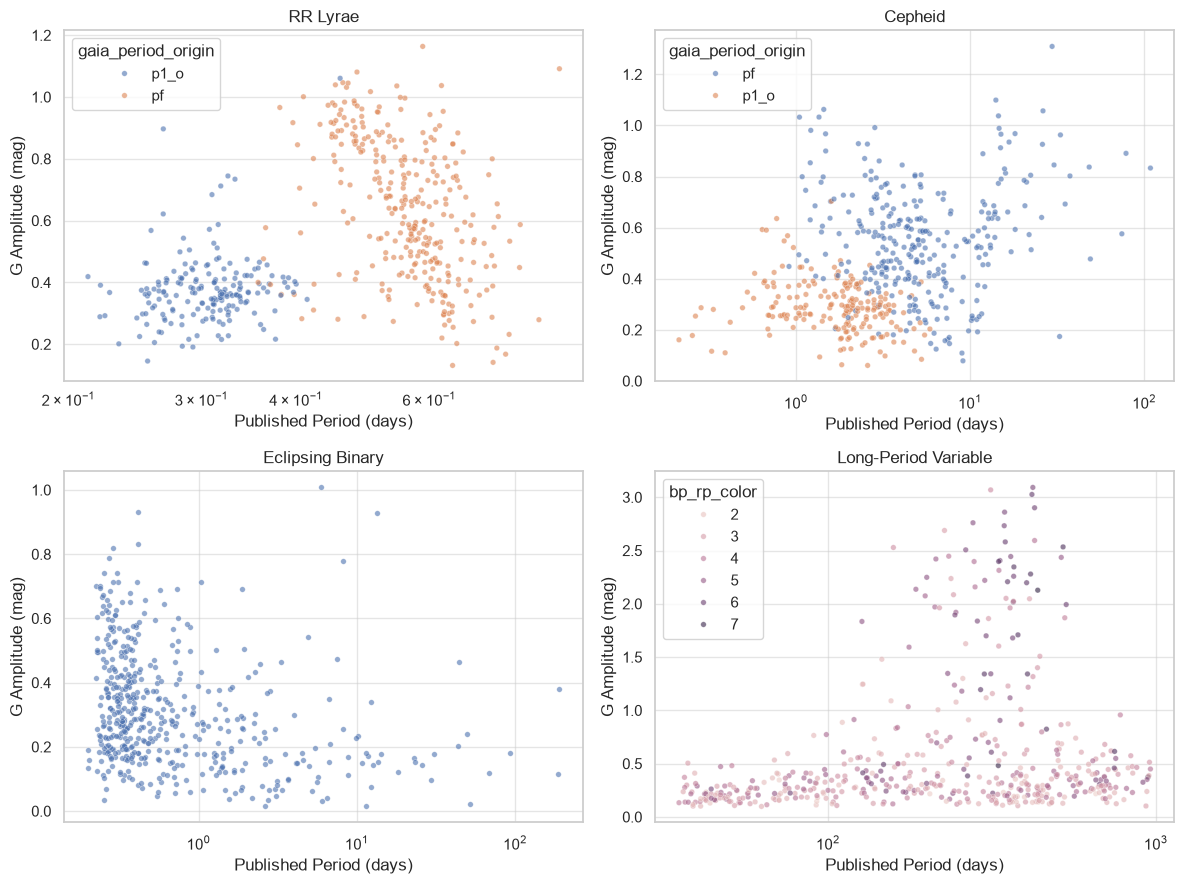

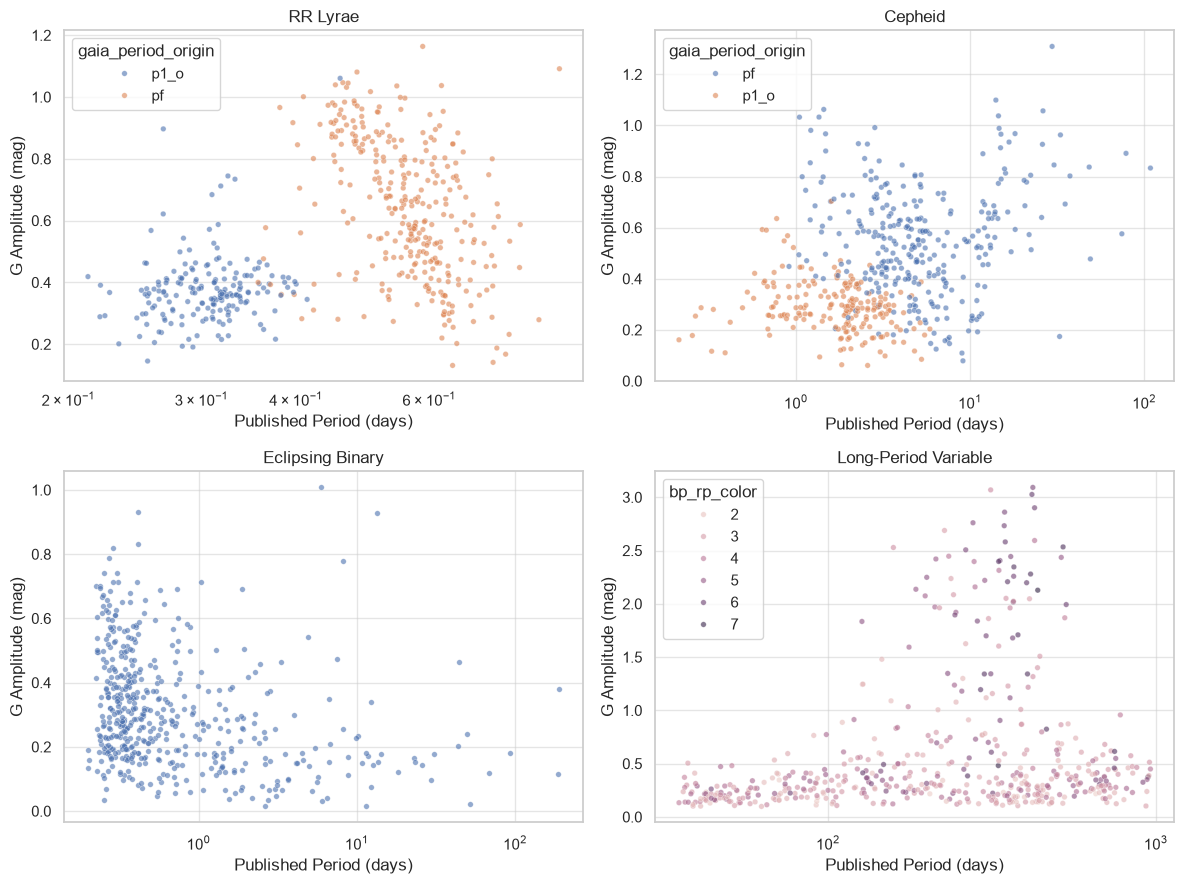

In [25]:
figure, axes = plt.subplots(2, 2, figsize=(12, 9))

for axis, name in zip(axes.flat, CLASSES):
    group = stars.loc[stars["class_name"].eq(name) & stars["gaia_period"].gt(0)]

    if name in ("RR Lyrae", "Cepheid"):
        sns.scatterplot(data=group, x="gaia_period", y="amplitude", hue="gaia_period_origin", s=16, alpha=0.6, ax=axis)
    elif name == "Long-Period Variable":
        sns.scatterplot(data=group, x="gaia_period", y="amplitude", hue="bp_rp_color", s=16, alpha=0.6, ax=axis)
    else:
        sns.scatterplot(data=group, x="gaia_period", y="amplitude", s=16, alpha=0.6, ax=axis)
    axis.set(xscale="log", xlabel="Published Period (days)", ylabel="G Amplitude (mag)", title=name)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "05_period_amplitude.png", dpi=160, bbox_inches="tight")
plt.show()

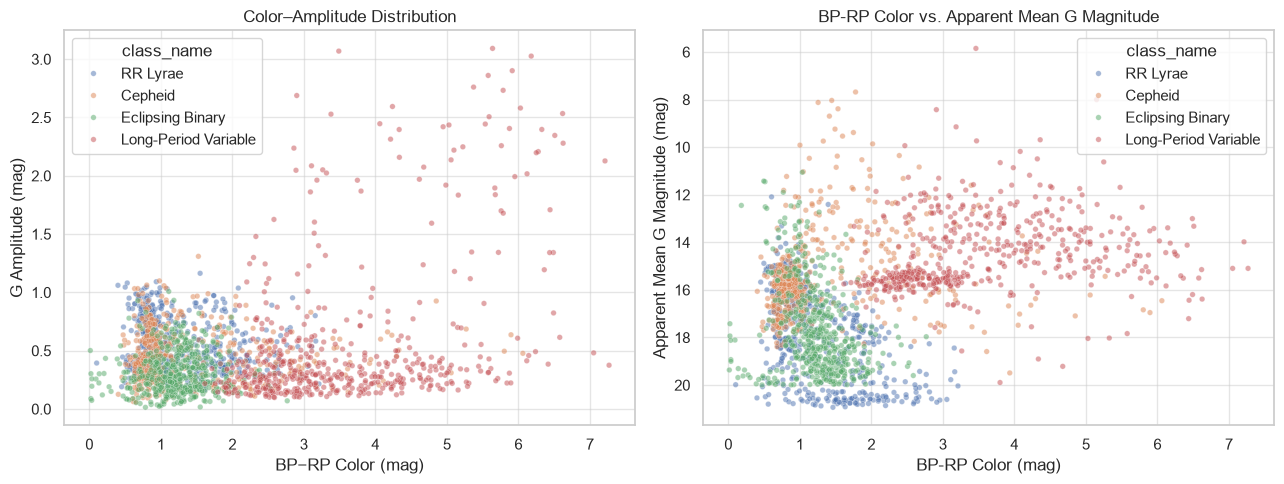

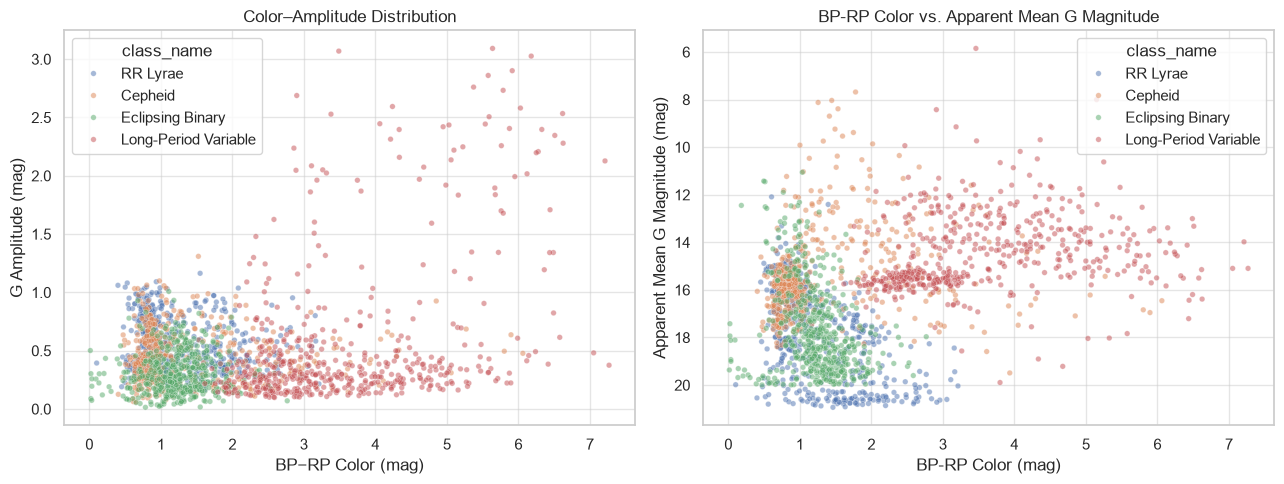

In [27]:
figure, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=stars, x="bp_rp_color", y="amplitude", hue="class_name", hue_order=CLASSES, alpha=0.5, s=16, ax=axes[0])
sns.scatterplot(data=stars, x="bp_rp_color", y="g_mean_magnitude", hue="class_name", hue_order=CLASSES, alpha=0.5, s=16, ax=axes[1])
axes[0].set(title="Color–Amplitude Distribution", xlabel="BP−RP Color (mag)", ylabel="G Amplitude (mag)")
axes[1].invert_yaxis()
axes[1].set(
    title="BP-RP Color vs. Apparent Mean G Magnitude",
    xlabel="BP-RP Color (mag)",
    ylabel="Apparent Mean G Magnitude (mag)"
)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "06_photometric_structure.png", dpi=160, bbox_inches="tight")
plt.show()

In [29]:
overlap = []

for name in CLASSES:
    group = stars.loc[stars["class_name"].eq(name), ["bp_rp_color", "amplitude"]].dropna()

    for comparison in CLASSES:
        if name == comparison:
            continue
        reference = stars.loc[stars["class_name"].eq(comparison), ["bp_rp_color", "amplitude"]].dropna()
        if group.empty or reference.empty:
            continue

        inside = group.ge(reference.quantile(0.05)).all(axis=1) & group.le(reference.quantile(0.95)).all(axis=1)
        overlap.append({"class_name": name, "comparison": comparison, "stars": len(group), "overlap_pct": 100 * inside.mean()})

display(pd.DataFrame(overlap).round(2))

,class_name,comparison,stars,overlap_pct
0,RR Lyrae,Cepheid,463,77.75
1,RR Lyrae,Eclipsing Binary,463,52.92
2,RR Lyrae,Long-Period Variable,463,10.80
3,Cepheid,RR Lyrae,500,63.60
4,Cepheid,Eclipsing Binary,500,61.40
5,Cepheid,Long-Period Variable,500,16.80
6,Eclipsing Binary,RR Lyrae,496,50.81
7,Eclipsing Binary,Cepheid,496,73.39
8,Eclipsing Binary,Long-Period Variable,496,1.61
9,Long-Period Variable,RR Lyrae,500,7.40


,class_name,comparison,stars,overlap_pct
0,RR Lyrae,Cepheid,463,77.75
1,RR Lyrae,Eclipsing Binary,463,52.92
2,RR Lyrae,Long-Period Variable,463,10.80
3,Cepheid,RR Lyrae,500,63.60
4,Cepheid,Eclipsing Binary,500,61.40
5,Cepheid,Long-Period Variable,500,16.80
6,Eclipsing Binary,RR Lyrae,496,50.81
7,Eclipsing Binary,Cepheid,496,73.39
8,Eclipsing Binary,Long-Period Variable,496,1.61
9,Long-Period Variable,RR Lyrae,500,7.40


## Final Data Audit

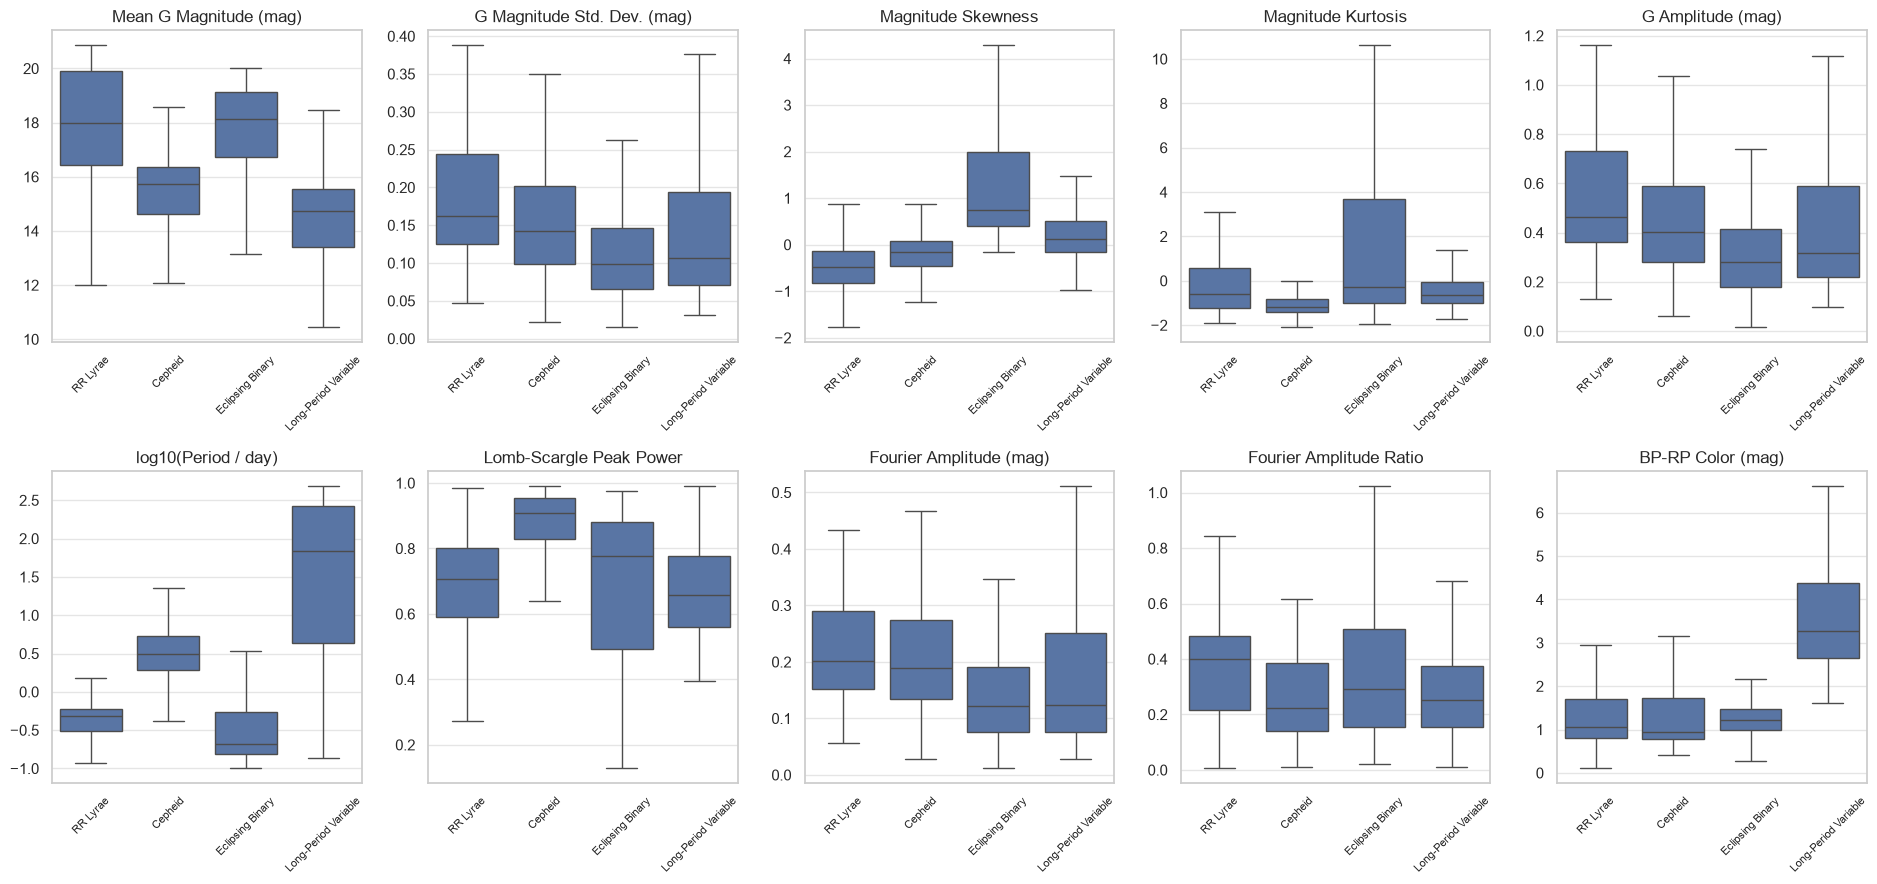

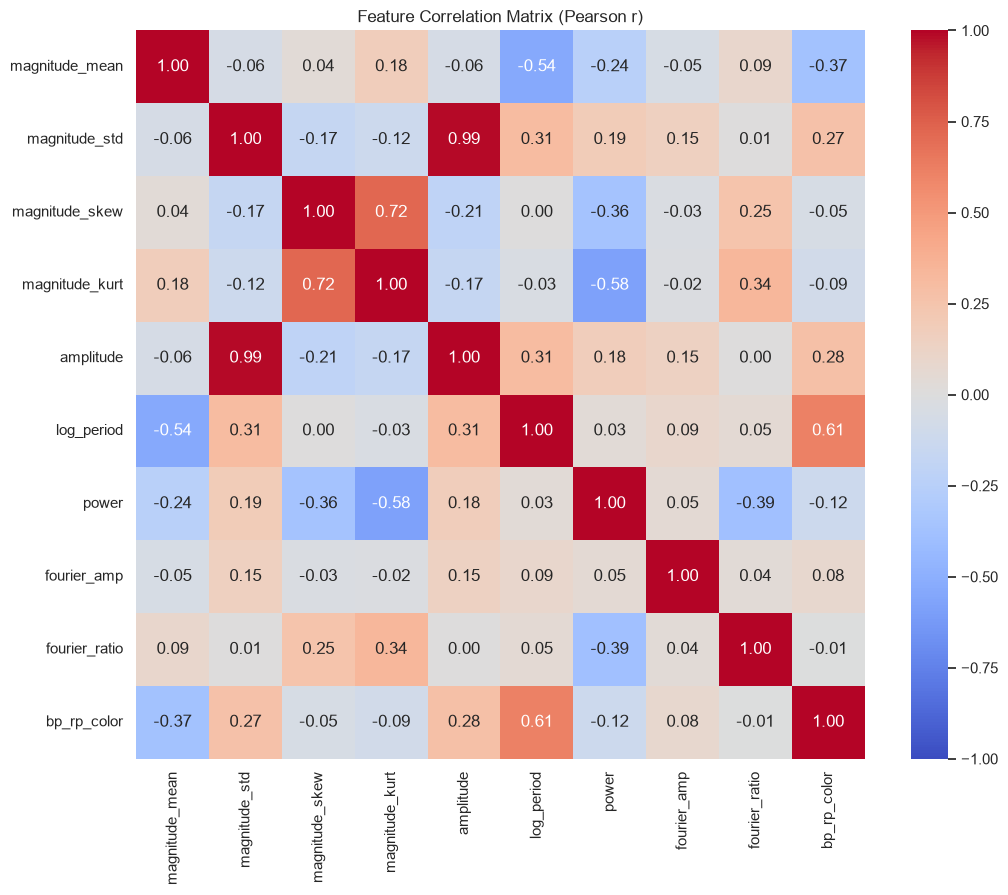

,magnitude_std,amplitude,fourier_amp
magnitude_std,1.000,0.990,0.152
amplitude,0.990,1.000,0.145
fourier_amp,0.152,0.145,1.000


In [31]:
fe_path = FEATURE_FILE.with_name("gaia_features_fe.csv")

if fe_path.exists():
    features = pd.read_csv(fe_path)

    feature_cols = [
        "magnitude_mean",
        "magnitude_std",
        "magnitude_skew",
        "magnitude_kurt",
        "amplitude",
        "log_period",
        "power",
        "fourier_amp",
        "fourier_ratio",
        "bp_rp_color"
    ]

    feature_labels = [
        "Mean G Magnitude (mag)",
        "G Magnitude Std. Dev. (mag)",
        "Magnitude Skewness",
        "Magnitude Kurtosis",
        "G Amplitude (mag)",
        "log10(Period / day)",
        "Lomb-Scargle Peak Power",
        "Fourier Amplitude (mag)",
        "Fourier Amplitude Ratio",
        "BP-RP Color (mag)"
    ]

    figure, axes = plt.subplots(2, 5, figsize=(19, 9))

    for axis, col, title in zip(axes.flat, feature_cols, feature_labels):
        sns.boxplot(
            data=features,
            x="class_name",
            y=col,
            order=CLASSES,
            showfliers=False,
            ax=axis
        )

        axis.set(
            title=title,
            xlabel="",
            ylabel=""
        )

        axis.tick_params(axis="x", rotation=45, labelsize=8)

    figure.tight_layout()
    figure.savefig(
        FIGURES_ROOT / "dist.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

    corr = features[feature_cols].corr(method="pearson")

    figure, axis = plt.subplots(figsize=(11, 9))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=axis
    )

    axis.set_title("Feature Correlation Matrix (Pearson r)")

    figure.tight_layout()
    figure.savefig(
        FIGURES_ROOT / "corr.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()

    display(
        corr.loc[
            ["magnitude_std", "amplitude", "fourier_amp"],
            ["magnitude_std", "amplitude", "fourier_amp"]
        ].round(3)
    )

else:
    print("Feature plots require the outputs from notebook 02.")

In [32]:
flow = pd.DataFrame({
    "initially_selected": sources["class_name"].value_counts(),
    "photometry_retrieved": sources.loc[
        sources["source_id"].isin(photometry["source_id"]),
        "class_name"
    ].value_counts(),
    "clean_photometry": sources.loc[
        sources["source_id"].isin(cleaned["source_id"]),
        "class_name"
    ].value_counts(),
    "minimum_epochs_pass": stars.loc[
        stars["usable"], "class_name"
    ].value_counts()
}).reindex(CLASSES).fillna(0).astype(int)

if fe_path.exists():
    modeled = pd.read_csv(
        fe_path,
        usecols=["source_id", "class_name"]
    )

    flow["final_modeling_cohort"] = (
        modeled["class_name"]
        .value_counts()
        .reindex(CLASSES, fill_value=0)
    )

    flow["other_feature_qc_exclusions"] = (
        flow["minimum_epochs_pass"]
        - flow["final_modeling_cohort"]
    )

flow["insufficient_epochs"] = (
    flow["clean_photometry"]
    - flow["minimum_epochs_pass"]
)

flow["no_clean_photometry"] = (
    flow["initially_selected"]
    - flow["clean_photometry"]
)

flow.loc["Total"] = flow.sum()

display(flow)

audit = pd.Series({
    "Initial Sources": len(sources),
    "Raw Observations": len(photometry),
    "Clean Observations": len(cleaned),
    "Sources Passing Minimum Epoch Count": int(stars["usable"].sum()),
    "Sources With Valid BP-RP Color": int(stars["bp_rp_color"].notna().sum())
})

if fe_path.exists():
    audit["Final Modeling Sources"] = len(modeled)

display(audit.to_frame("count"))

,initially_selected,photometry_retrieved,clean_photometry,minimum_epochs_pass,final_modeling_cohort,other_feature_qc_exclusions,insufficient_epochs,no_clean_photometry
class_name,,,,,,,,
RR Lyrae,500,500,500,478,478,0,22,0
Cepheid,500,500,500,500,500,0,0,0
Eclipsing Binary,500,500,500,500,500,0,0,0
Long-Period Variable,500,500,500,500,500,0,0,0
Total,2000,2000,2000,1978,1978,0,22,0


,count
Initial Sources,2000
Raw Observations,90126
Clean Observations,85243
Sources Passing Minimum Epoch Count,1978
Sources With Valid BP-RP Color,1959
Final Modeling Sources,1978
